 Dataset Loaded Successfully!
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Unique Gender values after encoding: [1 0]


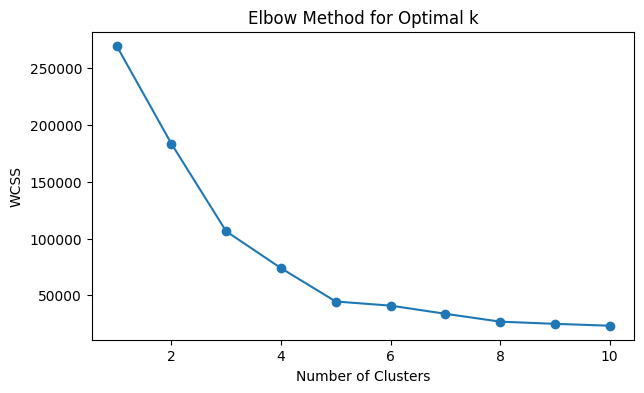

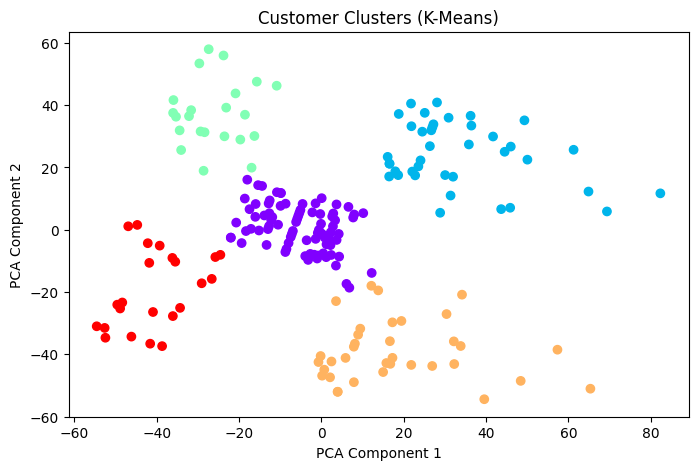


Evaluation Metrics:
Training Accuracy: 0.943
Testing Accuracy : 0.833

Confusion Matrix:
 [[29  3]
 [ 7 21]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.91      0.85        32
           1       0.88      0.75      0.81        28

    accuracy                           0.83        60
   macro avg       0.84      0.83      0.83        60
weighted avg       0.84      0.83      0.83        60



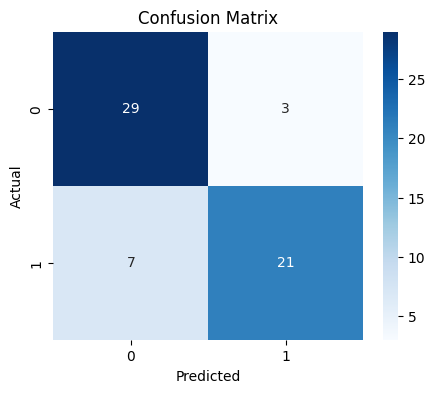

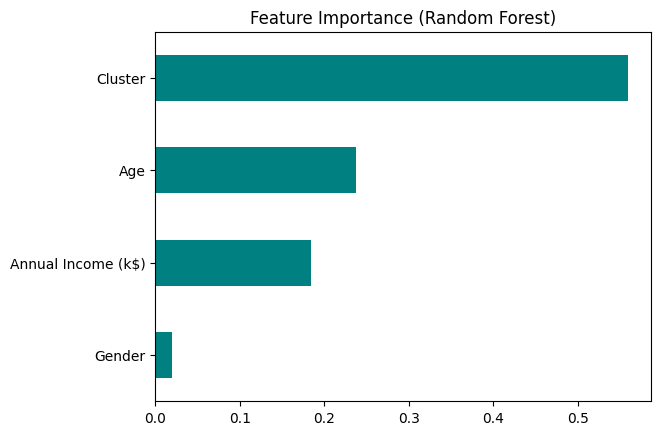

Enter Gender (Male/Female): Female
Enter Age: 3
Enter Annual Income (k$): 40000
Enter Spending Score (1-100): 45
The model predicts this customer is a LOW spender.


In [ ]:
# STEP 1 – Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# STEP 2 – Load Dataset
df = pd.read_csv("Mall_Customers[1].csv")
df.columns = df.columns.str.strip()
print(" Dataset Loaded Successfully!")
print(df.head())

# STEP 3 – Encode Gender/Genre Column
le = LabelEncoder()
if 'Genre' in df.columns:
    df['Gender'] = le.fit_transform(df['Genre'])
    df.drop('Genre', axis=1, inplace=True)
print("\nUnique Gender values after encoding:", df['Gender'].unique())

# STEP 4 – Unsupervised Learning (K-Means Clustering)
X_unsupervised = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Determine optimal clusters using Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_unsupervised)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()
print("\n")
print("\n")

# Apply K-Means with k=5
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
df['Cluster'] = kmeans.fit_predict(X_unsupervised)

# Visualize clusters using PCA
pca = PCA(n_components=2)
reduced = pca.fit_transform(X_unsupervised)
plt.figure(figsize=(8,5))
plt.scatter(reduced[:,0], reduced[:,1], c=df['Cluster'], cmap='rainbow')
plt.title('Customer Clusters (K-Means)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

# STEP 5 – Create Binary Target for Classification
df['HighSpender'] = df['Spending Score (1-100)'].apply(lambda x: 1 if x > 50 else 0)

# STEP 6 – Define Features & Labels
X = df[['Gender', 'Age', 'Annual Income (k$)', 'Cluster']]
y = df['HighSpender']

# STEP 7 – Scale Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# STEP 8 – Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

# STEP 9 – Train Random Forest
rf = RandomForestClassifier(
    n_estimators=50,      # fewer trees
    max_depth=5,          # limit tree depth
    min_samples_split=5,  # min samples to split
    min_samples_leaf=2,   # min samples in leaf
    max_features='sqrt',  # limit features per tree
    bootstrap=True,
    random_state=42
)
rf.fit(X_train, y_train)

# STEP 10 – Predictions
y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)

# STEP 11 – Evaluation
print("\nEvaluation Metrics:")
print(f"Training Accuracy: {accuracy_score(y_train, y_pred_train):.3f}")
print(f"Testing Accuracy : {accuracy_score(y_test, y_pred_test):.3f}")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_test))
print("\nClassification Report:\n", classification_report(y_test, y_pred_test))

# Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print("\n")
print("\n")

# STEP 12 – Feature Importance
feature_importances = pd.Series(rf.feature_importances_, index=['Gender', 'Age', 'Annual Income (k$)', 'Cluster'])
feature_importances.sort_values().plot(kind='barh', color='teal')
plt.title('Feature Importance (Random Forest)')
plt.show()

# STEP 13 – User Input Prediction (Automatic Cluster, No Warnings)
gender_input = input("Enter Gender (Male/Female): ").strip().lower()
age_input = float(input("Enter Age: "))
income_input = float(input("Enter Annual Income (k$): "))
spending_input = float(input("Enter Spending Score (1-100): "))

# Encode Gender
gender_value = 1 if gender_input == 'male' else 0

# Prepare user input for KMeans
user_df = pd.DataFrame({
    'Annual Income (k$)': [income_input],
    'Spending Score (1-100)': [spending_input]
})

# Automatically predict cluster
user_cluster = kmeans.predict(user_df)[0]

# Prepare feature DataFrame for Random Forest
rf_input_df = pd.DataFrame({
    'Gender': [gender_value],
    'Age': [age_input],
    'Annual Income (k$)': [income_input],
    'Cluster': [user_cluster]
})

# Scale features
user_data_scaled = scaler.transform(rf_input_df)

# Predict
prediction = rf.predict(user_data_scaled)

# Display Result
if prediction[0] == 1:
    print("The model predicts this customer is a HIGH spender.")
else:
    print("The model predicts this customer is a LOW spender.")
